# Time-Series EDA — Myanmar Rice Prices

## 1. Objective and scope

This notebook investigates the historical monthly retail price of **low-quality rice in Pakokku Myo Ma Market**. The immediate modelling question is:

> Can historical monthly prices help us forecast the next month's price in this market?

The notebook focuses on understanding the target series before building forecasting features or models. It does not attempt to explain the causes of individual price movements.

### Selected series

| Field | Selection |
|---|---|
| Commodity | Rice (low quality) |
| Market | Pakokku Myo Ma Market |
| Market ID | `1664` |
| Price type | Retail |
| Unit | KG |
| Currency | MMK |
| Period | January 2014 – September 2026 |

**Why Pakokku?** The selected series contains 146 observed months out of 153 calendar months (95.4% coverage). It has fewer missing months than the previously considered Lashio series (23 missing months; 89.8% coverage). Pakokku is therefore the more practical primary case study for this midterm.

**Scope decision:** Other markets are used only as supporting context. The forecasting target remains Pakokku. Kanthar has been removed from this notebook's comparison because it is no longer part of the current project scope.

In [1]:
# 2. Environment and configuration

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/prices.csv")

TARGET_COMMODITY = "Rice (low quality)"
TARGET_UNIT = "KG"
TARGET_PRICE_TYPE = "Retail"
TARGET_CURRENCY = "MMK"
PAKOKKU_ID = 1664

## 3. Load, filter, and aggregate the data

The raw data is filtered to the selected commodity, market attributes, and currency. Records are then aggregated to one monthly price per market.

The monthly price is the **mean of the available observations in that month**. `observation_count` is retained so that unusual monthly movements can be checked against the number of underlying records.

In [2]:
# Load and standardize the raw dataset
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Check the notebook working directory and DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

required_columns = {
    "date", "commodity", "market_id", "market",
    "unit", "pricetype", "currency", "price"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

# Keep the target commodity and comparable price observations
rice_df = df[
    (df["commodity"] == TARGET_COMMODITY)
    & (df["unit"] == TARGET_UNIT)
    & (df["pricetype"] == TARGET_PRICE_TYPE)
    & (df["currency"] == TARGET_CURRENCY)
].dropna(subset=["date", "price"]).copy()

rice_df["month"] = rice_df["date"].dt.to_period("M")

# One row per market-month
monthly_rice = (
    rice_df.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        observation_count=("price", "count")
    )
    .reset_index()
    .sort_values(["market_id", "month"])
)

print("Filtered raw observations:", len(rice_df))
print("Monthly market-price rows:", len(monthly_rice))
print("Markets represented:", monthly_rice["market_id"].nunique())

# Select Pakokku and restore its complete monthly calendar
df_pakokku = (
    monthly_rice[monthly_rice["market_id"] == PAKOKKU_ID]
    .sort_values("month")
    .set_index("month")
    .copy()
)

if df_pakokku.empty:
    raise ValueError(f"No rice observations found for market ID {PAKOKKU_ID}.")

full_month_index = pd.period_range(
    start=df_pakokku.index.min(),
    end=df_pakokku.index.max(),
    freq="M"
)

df_pakokku = df_pakokku.reindex(full_month_index)
df_pakokku.index.name = "month"

print("First month:", df_pakokku.index.min())
print("Last month:", df_pakokku.index.max())
print("Calendar months:", len(df_pakokku))
print("Observed price months:", df_pakokku["monthly_price"].notna().sum())
print("Missing months:", df_pakokku["monthly_price"].isna().sum())
print("Coverage (%):", round(df_pakokku["monthly_price"].notna().mean() * 100, 1))

display(
    df_pakokku.loc[
        df_pakokku["monthly_price"].isna(),
        ["monthly_price", "observation_count"]
    ]
)

Filtered raw observations: 10231
Monthly market-price rows: 10231
Markets represented: 298
First month: 2014-01
Last month: 2026-09
Calendar months: 153
Observed price months: 146
Missing months: 7
Coverage (%): 95.4


,monthly_price,observation_count
month,,
2015-05,NaN,NaN
2015-06,NaN,NaN
2015-07,NaN,NaN
2019-05,NaN,NaN
2019-06,NaN,NaN
2020-02,NaN,NaN
2025-01,NaN,NaN


### 3.1 Coverage and missing observations

The selected period contains **153 calendar months**, of which **146 have observed prices**. This gives **95.4% coverage**, with seven missing months:

- May–July 2015
- May–June 2019
- February 2020
- January 2025

These are missing observations, not known zero prices. We will not interpolate them or manufacture target values for the initial forecasting baseline. When lag features are created, rows without the required historical observations should be excluded from model training.

A missing month also breaks a consecutive-month comparison: for example, a price in February must not be compared with December as though only one month had elapsed.

In [3]:
# Summarize consecutive runs of missing months
missing_periods = df_pakokku.index[df_pakokku["monthly_price"].isna()]

missing_runs = []
if len(missing_periods):
    run_start = previous = missing_periods[0]
    for period in missing_periods[1:]:
        if period == previous + 1:
            previous = period
        else:
            missing_runs.append((run_start, previous))
            run_start = previous = period
    missing_runs.append((run_start, previous))

missing_runs_df = pd.DataFrame(
    [
        {
            "start_month": str(start),
            "end_month": str(end),
            "months_missing": (end - start).n + 1
        }
        for start, end in missing_runs
    ]
)

display(missing_runs_df)

,start_month,end_month,months_missing
0,2015-05,2015-07,3
1,2019-05,2019-06,2
2,2020-02,2020-02,1
3,2025-01,2025-01,1


## 4. Overall price movement

The first plot shows the observed monthly prices across the full study period. Gaps are intentionally left visible.

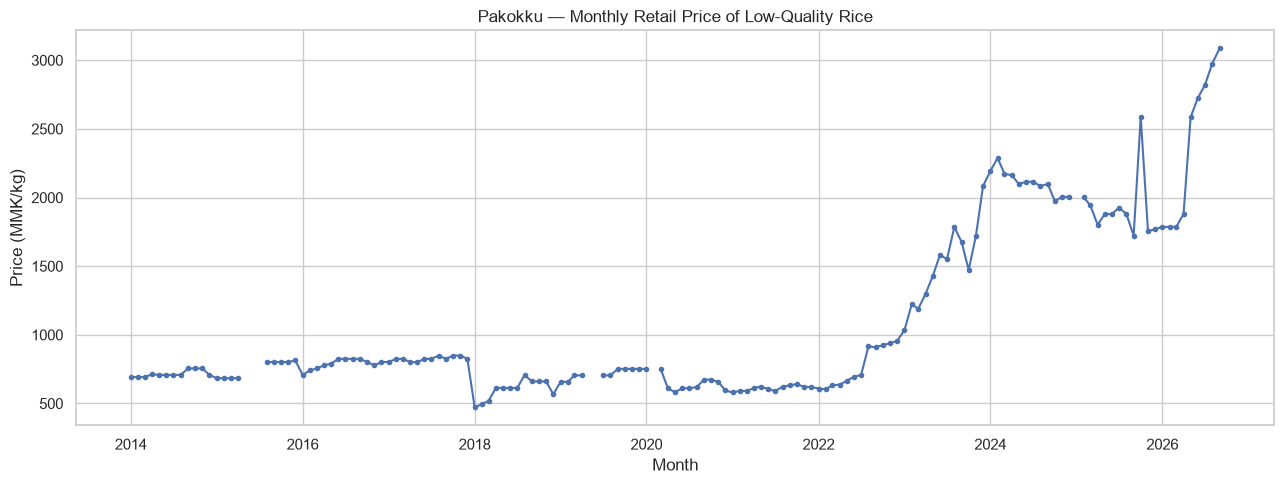

In [4]:
plt.figure(figsize=(13, 5))
plt.plot(
    df_pakokku.index.to_timestamp(),
    df_pakokku["monthly_price"],
    markersize=3,
    linewidth=1.5,
    marker="o"
)
plt.title("Pakokku — Monthly Retail Price of Low-Quality Rice")
plt.xlabel("Month")
plt.ylabel("Price (MMK/kg)")
plt.tight_layout()
plt.show()

### Observation

The series does not follow one smooth upward path. It contains relatively stable stretches, declines, sharp increases, and periods of faster movement. This makes it important to evaluate simple time-based baselines and to use chronological validation rather than a random train/test split.

The plot alone does not establish why a price changed. The notebook therefore treats unusual movements as points for data verification, not as confirmed economic events.

## 5. Rolling averages

Three-month and twelve-month rolling means help distinguish short-term movement from the broader direction of the series. They are descriptive summaries, not forecasts.

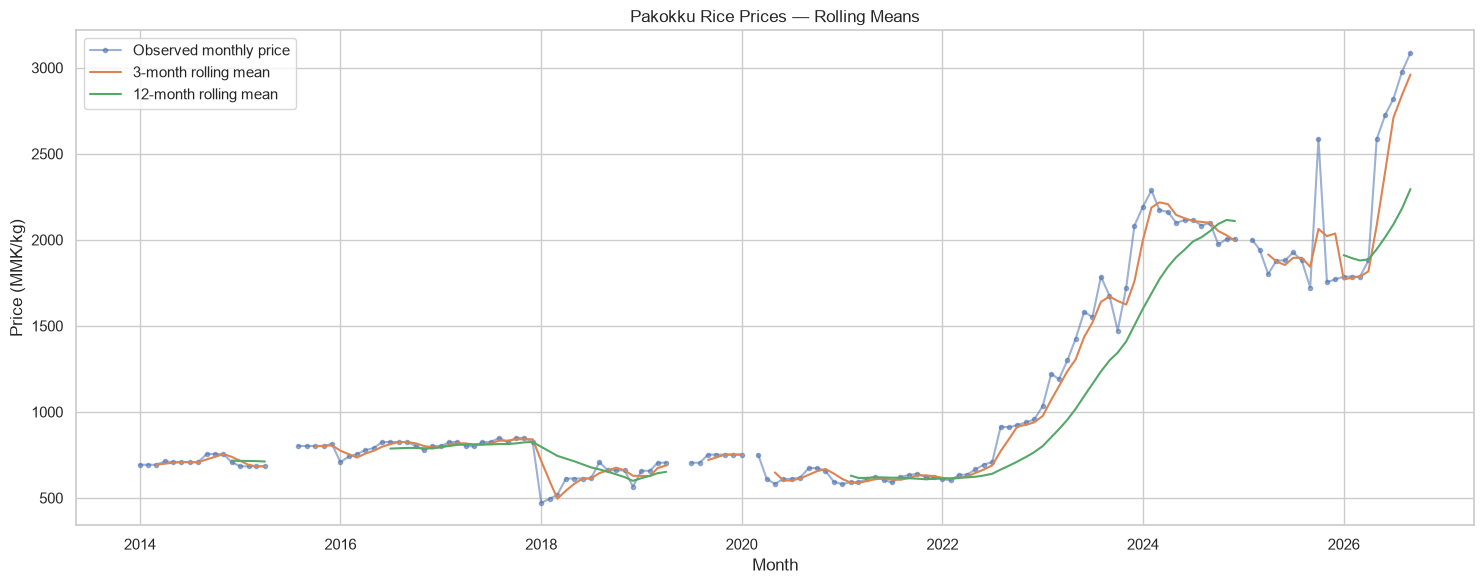

In [5]:
df_pakokku["rolling_mean_3"] = (
    df_pakokku["monthly_price"]
    .rolling(window=3, min_periods=3)
    .mean()
)

df_pakokku["rolling_mean_12"] = (
    df_pakokku["monthly_price"]
    .rolling(window=12, min_periods=12)
    .mean()
)

plt.figure(figsize=(15, 6))
plt.plot(
    df_pakokku.index.to_timestamp(),
    df_pakokku["monthly_price"],
    label="Observed monthly price",
    alpha=0.55,
    marker="o",
    markersize=3
)
plt.plot(
    df_pakokku.index.to_timestamp(),
    df_pakokku["rolling_mean_3"],
    label="3-month rolling mean"
)
plt.plot(
    df_pakokku.index.to_timestamp(),
    df_pakokku["rolling_mean_12"],
    label="12-month rolling mean"
)
plt.title("Pakokku Rice Prices — Rolling Means")
plt.xlabel("Month")
plt.ylabel("Price (MMK/kg)")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

- The **3-month rolling mean** responds more quickly to recent changes.
- The **12-month rolling mean** is smoother and gives more weight to the longer-term level.
- Because the rolling calculations require complete windows (`min_periods` equals the window size), missing observations create gaps in the rolling means. This is intentional; the missing months are not filled.

The sustained rise in the later part of the series is visible in the longer rolling mean, while sharp monthly movements are more apparent in the raw series.

## 6. Month-to-month price changes

Percentage change is calculated only when the current month and the immediately preceding calendar month both have observed prices. `fill_method=None` prevents pandas from silently carrying a previous value across a missing month.

In [6]:
df_pakokku["monthly_change_pct"] = (
    df_pakokku["monthly_price"]
    .pct_change(fill_method=None)
    .mul(100)
)

valid_changes = df_pakokku["monthly_change_pct"].dropna()

change_summary = pd.Series({
    "valid_consecutive_month_pairs": valid_changes.count(),
    "zero_change_rate_pct": valid_changes.eq(0).mean() * 100,
    "median_absolute_change_pct": valid_changes.abs().median(),
    "90th_percentile_absolute_change_pct": valid_changes.abs().quantile(0.90),
    "maximum_absolute_change_pct": valid_changes.abs().max()
})

display(change_summary.to_frame("value").round(2))

,value
valid_consecutive_month_pairs,141.00
zero_change_rate_pct,25.53
median_absolute_change_pct,2.50
90th_percentile_absolute_change_pct,13.02
maximum_absolute_change_pct,50.15


### Large observed movements

The following months have an absolute month-to-month change greater than 20%.

In [7]:
large_moves = (
    df_pakokku.loc[
        df_pakokku["monthly_change_pct"].abs() > 20,
        ["monthly_price", "monthly_change_pct", "observation_count"]
    ]
    .copy()
)

display(large_moves.round(2))

,monthly_price,monthly_change_pct,observation_count
month,,,
2018-01,472.0,-42.79,1.0
2022-08,915.0,29.24,1.0
2023-12,2083.0,20.89,1.0
2025-10,2587.0,50.15,1.0
2025-11,1754.0,-32.20,1.0
2026-05,2585.0,37.50,1.0


### Findings from the Pakokku series

| Month | Monthly price (MMK/kg) | Change from previous month |
|---|---:|---:|
| 2018-01 | 472 | −42.79% |
| 2022-08 | 915 | +29.24% |
| 2023-12 | 2,083 | +20.89% |
| 2025-10 | 2,587 | +50.15% |
| 2025-11 | 1,754 | −32.20% |
| 2026-05 | 2,585 | +37.50% |

The largest movement in this list is the **+50.15% increase in October 2025**, followed by a **−32.20% decrease in November 2025**. These are substantial changes, but a percentage change by itself does not tell us whether the record is erroneous or what caused it.

## 7. Verify unusual observations against the source records

Before treating a large movement as an error or removing it, inspect the underlying raw records and the number of observations used to calculate the monthly mean.

In [8]:
unusual_months = [
    "2018-01",
    "2022-08",
    "2023-12",
    "2025-10",
    "2025-11",
    "2026-05",
]

unusual_records = rice_df[
    (rice_df["market_id"] == PAKOKKU_ID)
    & (rice_df["month"].astype(str).isin(unusual_months))
].sort_values("date")

display(
    unusual_records[
        [
            "date",
            "commodity",
            "market",
            "unit",
            "pricetype",
            "currency",
            "price",
        ]
    ]
)

display(
    df_pakokku.loc[
        pd.PeriodIndex(unusual_months, freq="M"),
        ["monthly_price", "observation_count"]
    ]
)

,date,commodity,market,unit,pricetype,currency,price
16926,2018-01-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,472.0
33817,2022-08-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,915.0
44694,2023-12-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,2083.0
55521,2025-10-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,2587.0
55944,2025-11-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,1754.0
59036,2026-05-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,2585.0


,monthly_price,observation_count
month,,
2018-01,472.0,1.0
2022-08,915.0,1.0
2023-12,2083.0,1.0
2025-10,2587.0,1.0
2025-11,1754.0,1.0
2026-05,2585.0,1.0


### Data-verification result

The six unusual months each have **one underlying source observation**. The records are consistently labelled as `Rice (low quality)`, `KG`, `Retail`, and `MMK`. No confirmed data-entry or category error was identified in this check.

**Decision:** retain these observations in the dataset for now. Do not delete or winsorize them merely because their percentage changes are large. Their single-record basis should, however, be documented as a limitation when interpreting the monthly averages.

## 8. Supporting cross-market research (context only)

The primary forecasting target remains Pakokku. A limited comparison with Hlaing Bwe, Kalaw, and Taunggyi was used to check whether large movements were shared across markets. Kanthar is intentionally excluded from this revised scope.

### October–November 2025 comparison

| Market | October 2025 change | November 2025 change |
|---|---:|---:|
| Hlaing Bwe | +2.08% | +29.95% |
| Kalaw | −4.11% | −24.29% |
| Pakokku | +50.15% | −32.20% |
| Taunggyi | +1.43% | −30.28% |

The movements are heterogeneous: the markets did not all move in the same direction or by similar magnitudes. This comparison does **not** support describing Pakokku's October 2025 jump as a uniform national price movement.

### Four-market change diagnostics

The exploratory diagnostics below use consecutive calendar-month pairs only.

| Market | Observed months | Valid pairs | Zero-change rate | Median absolute change | 90th percentile | Maximum absolute change |
|---|---:|---:|---:|---:|---:|---:|
| Hlaing Bwe | 77 | 75 | 8.00% | 7.13% | 22.45% | 37.84% |
| Kalaw | 48 | 46 | 8.70% | 4.35% | 22.12% | 94.44% |
| Pakokku | 146 | 141 | 25.53% | 2.50% | 13.02% | 50.15% |
| Taunggyi | 108 | 91 | 30.77% | 5.88% | 22.22% | 66.67% |

These diagnostics are descriptive and should be interpreted with coverage in mind. In particular, a high zero-change rate does not automatically mean a market is more stable: repeated unchanged reported prices and sparse observations can affect the statistic. The comparison is supporting context, not a reason to change the single-market forecasting target.

## 9. EDA conclusions and modelling implications

1. **Forecasting target:** monthly retail price of low-quality rice in Pakokku Myo Ma Market (MMK/kg).
2. **Coverage:** 146 observed months across 153 calendar months (95.4%); seven months are missing.
3. **Missing data:** preserve missing months as missing. Do not interpolate target prices for the first baseline.
4. **Price behaviour:** the series contains long-term upward movement as well as sharp short-term changes.
5. **Unusual observations:** six large movements were checked against raw records. Each month has one source observation; no confirmed error was found, so retain them.
6. **Market context:** the limited comparison shows heterogeneous movements across markets, so Pakokku's large changes should not be assumed to represent a uniform national movement.
7. **Validation:** use chronological train/validation/test splits. Random splitting would leak future time periods into the training process.
8. **Baselines:** compare against simple forecasts such as the last observed price and a moving-average baseline before testing more complex models.

### Next modelling stage

Create lag-based features only from information available before the forecast month. Exclude rows where required lag values are missing, and evaluate predictions against a chronological holdout. Any feature engineering and imputation must be fitted using training data only.